# Tutorial Management System — Exploratory Data Analysis (EDA)

This notebook analyzes tutorial records served by the Spring Boot REST API. It uses **pandas** for preparation and analysis and **matplotlib** for visualizations.

## Exploratory Data Analysis (EDA) Overview

This section documents the structured exploration of the tutorial dataset retrieved dynamically from the Spring Boot backend REST API. The primary objective is to evaluate data hygiene, analyze content distribution, measure contributor activity, and examine text length patterns.

### Key Analysis Components

* **Data Hygiene & Structural Inspection:**
* Verifies dataset dimensions, checks for missing or null values, and inspects data types to ensure complete data integrity before downstream modeling or reporting.


* **Published Status Distribution:**
* Evaluates the proportion of active versus draft tutorials (`published` boolean flag) using frequency counts and a proportional pie chart to understand content readiness.


* **Contributor Productivity Analysis:**
* Identifies top-performing creators contributing the highest volume of tutorials to the system, visualized via sorted horizontal bar charts.


* **Text Length Characterization:**
* Computes character length metrics for text fields (`title` and `description`) to understand typical content size distributions and formatting variations across entries.


* **Creator Publishing Success:**
* Utilizes cross-tabulation and stacked bar charts to compare publishing output across top contributors, highlighting individual workflow patterns.


In [1]:
# --- IMPORT LIBRARIES & CONFIGURE ENVIRONMENT ---
import json
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
import json, textwrap

In [2]:
# Setup visual configurations for tables and charts
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

In [3]:
# Load data directly from the REST API
url = "http://localhost:8888/api/all"
df = pd.read_json(url)

# Inspect the dataset
print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (100, 5)


,creator,description,id,published,title
0,Emil Gutmann,Accusantium excepturi molestiae magnam et necessitatibus.,1,False,The Green Bay Tree
1,Astrid Nicolas,Ipsum voluptatem voluptas et.,2,True,Fear and Trembling
2,Hwa Kris,Ut cum tenetur alias dolorem quos.,3,True,That Good Night
3,Frankie Padberg,Totam et nulla.,4,True,Tirra Lirra by the River
4,Simona Toy,Iure molestias itaque cum nobis eligendi consequatur.,5,False,The Doors of Perception


<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   creator      100 non-null    str  
 1   description  100 non-null    str  
 2   id           100 non-null    int64
 3   published    100 non-null    bool 
 4   title        100 non-null    str  
dtypes: bool(1), int64(1), str(3)
memory usage: 3.4 KB


None

In [4]:
# Preserve the original dataset
df_raw = df.copy()
# Inspect columns and data types
print(df.columns)
print(df.dtypes)
# Check missing values
display(df.isnull().sum())
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())
# Summary statistics
display(df.describe(include="all"))

Index(['creator', 'description', 'id', 'published', 'title'], dtype='str')
creator          str
description      str
id             int64
published       bool
title            str
dtype: object


creator        0
description    0
id             0
published      0
title          0
dtype: int64

Duplicate rows: 0


,creator,description,id,published,title
count,100,100,100.000000,100,100
unique,100,100,NaN,2,78
top,Emil Gutmann,Accusantium excepturi molestiae magnam et necessitatibus.,NaN,True,Consider Phlebas
freq,1,1,NaN,61,3
mean,NaN,NaN,50.500000,NaN,NaN
std,NaN,NaN,29.011492,NaN,NaN
min,NaN,NaN,1.000000,NaN,NaN
25%,NaN,NaN,25.750000,NaN,NaN
50%,NaN,NaN,50.500000,NaN,NaN
75%,NaN,NaN,75.250000,NaN,NaN


In [5]:
df = pd.read_json('http://localhost:8888/api/all')
df

,creator,description,id,published,title
0,Emil Gutmann,Accusantium excepturi molestiae magnam et necessitatibus.,1,False,The Green Bay Tree
1,Astrid Nicolas,Ipsum voluptatem voluptas et.,2,True,Fear and Trembling
2,Hwa Kris,Ut cum tenetur alias dolorem quos.,3,True,That Good Night
3,Frankie Padberg,Totam et nulla.,4,True,Tirra Lirra by the River
4,Simona Toy,Iure molestias itaque cum nobis eligendi consequatur.,5,False,The Doors of Perception
...,...,...,...,...,...
95,Elbert Lynch,Et sint sint.,96,False,I Know Why the Caged Bird Sings
96,Edmundo Raynor,Animi autem voluptates officiis adipisci aperiam.,97,True,I Sing the Body Electric
97,Christopher Erdman,Ut ea eius.,98,False,Death Be Not Proud
98,Dr. Santos Simonis,At ad rem autem quis officia aut.,99,False,Tender Is the Night


## 1. Published Status Distribution (Proportion Analysis)
> Analyze how many tutorials are published versus unpublished using a pie chart and count summary.

Published Status Breakdown:
published
True     61
False    39
Name: count, dtype: int64


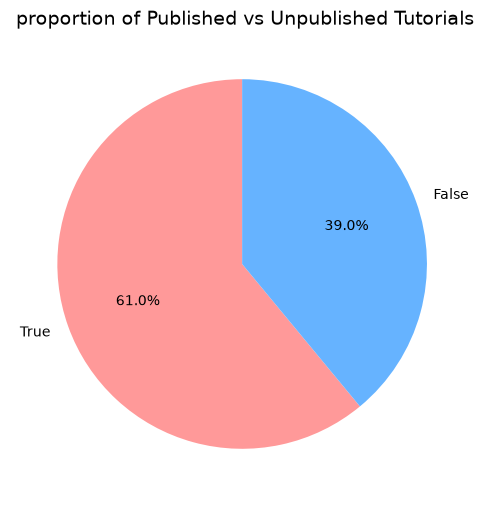

In [6]:
# Value counts for published status
published_counts = df['published'].value_counts()
print("Published Status Breakdown:")
print(published_counts)

# Visualization: Pie Chart
fig, ax = plt.subplots(figsize=(6, 6))
published_counts.plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90,
    colors=['#ff9999', '#66b3ff'],
    ax=ax,
)
ax.set_ylabel('')
plt.title(' proportion of Published vs Unpublished Tutorials')
plt.show()

## 2. Top Creators Analysis
> Find out which creators have contributed the most tutorials to the system and visualize the top performers.

Top 10 Creators:
creator
Emil Gutmann            1
Astrid Nicolas          1
Hwa Kris                1
Frankie Padberg         1
Simona Toy              1
Geoffrey Hauck          1
Kyle Hettinger          1
Adalberto Vandervort    1
Matha Kovacek           1
Chadwick Fadel          1
Name: count, dtype: int64


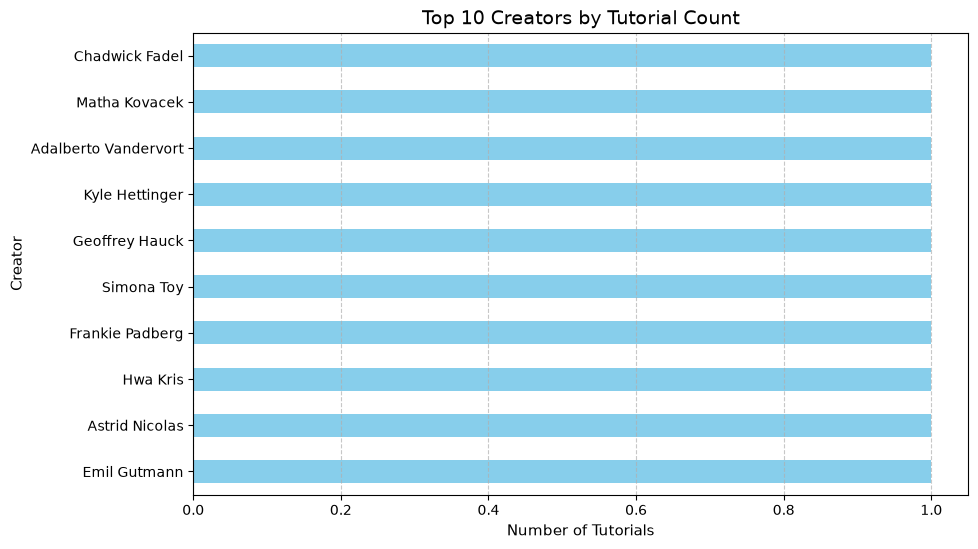

In [7]:
# Top 10 creators by tutorial count
top_creators = df['creator'].value_counts().head(10)
print('Top 10 Creators:')
print(top_creators)

# Visualization: Horizontal Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))
top_creators.sort_values().plot(kind='barh', color='skyblue', ax=ax)
ax.set_title('Top 10 Creators by Tutorial Count')
ax.set_xlabel('Number of Tutorials')
ax.set_ylabel('Creator')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()

## 3. Text Length Analysis (Title & Description)
> Examine the length characteristics of your text fields (title and description) to see average text sizes.

,title_length,description_length
count,100.000000,100.000000
mean,20.020000,37.820000
std,6.424354,13.761592
min,10.000000,11.000000
25%,16.000000,27.000000
50%,18.500000,39.000000
75%,23.000000,49.000000
max,49.000000,70.000000


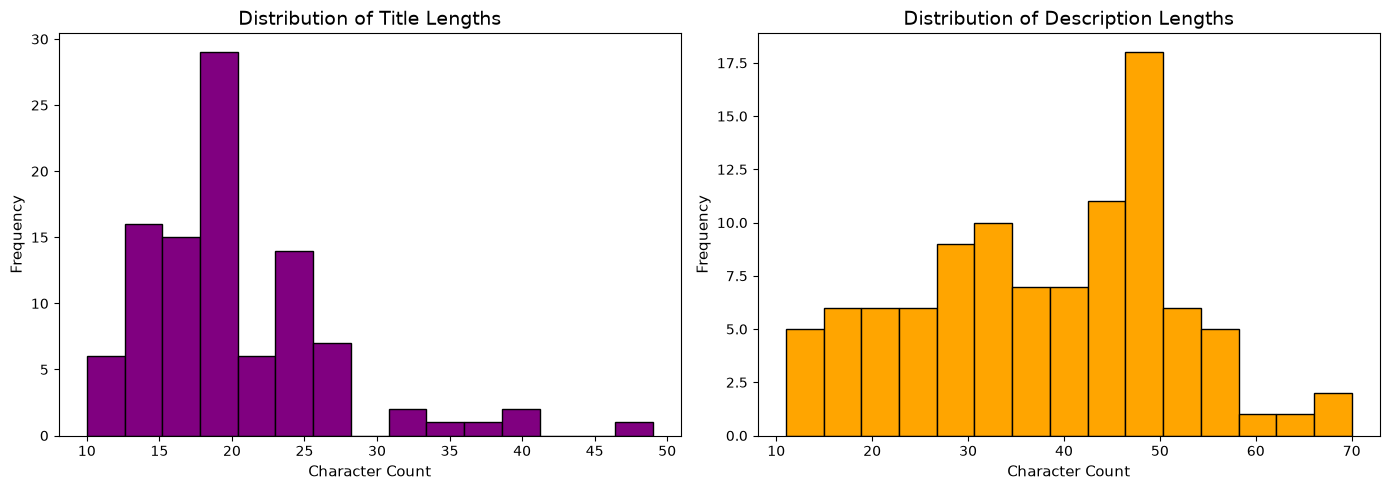

In [8]:
# Create new feature columns for length
df['title_length'] = df['title'].str.len()
df['description_length'] = df['description'].str.len()

# Summary statistics for text lengths
display(df[['title_length', 'description_length']].describe())

# Visualization: Histograms
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['title_length'].plot(
    kind='hist', bins=15, color='purple', edgecolor='black', ax=axes[0]
)
axes[0].set_title('Distribution of Title Lengths')
axes[0].set_xlabel('Character Count')

df['description_length'].plot(
    kind='hist', bins=15, color='orange', edgecolor='black', ax=axes[1]
)
axes[1].set_title('Distribution of Description Lengths')
axes[1].set_xlabel('Character Count')

plt.tight_layout()
plt.show()

## 4. Creator Publishing Success (Stacked Bar Chart)
> Compare whether specific top creators have a higher proportion of published tutorials versus unpublished ones.

Creator vs Published Status Crosstab:


published,False,True
creator,,
Adalberto Vandervort,0,1
Astrid Nicolas,0,1
Chadwick Fadel,0,1
Emil Gutmann,1,0
Frankie Padberg,0,1
Geoffrey Hauck,1,0
Hwa Kris,0,1
Kyle Hettinger,1,0
Matha Kovacek,0,1


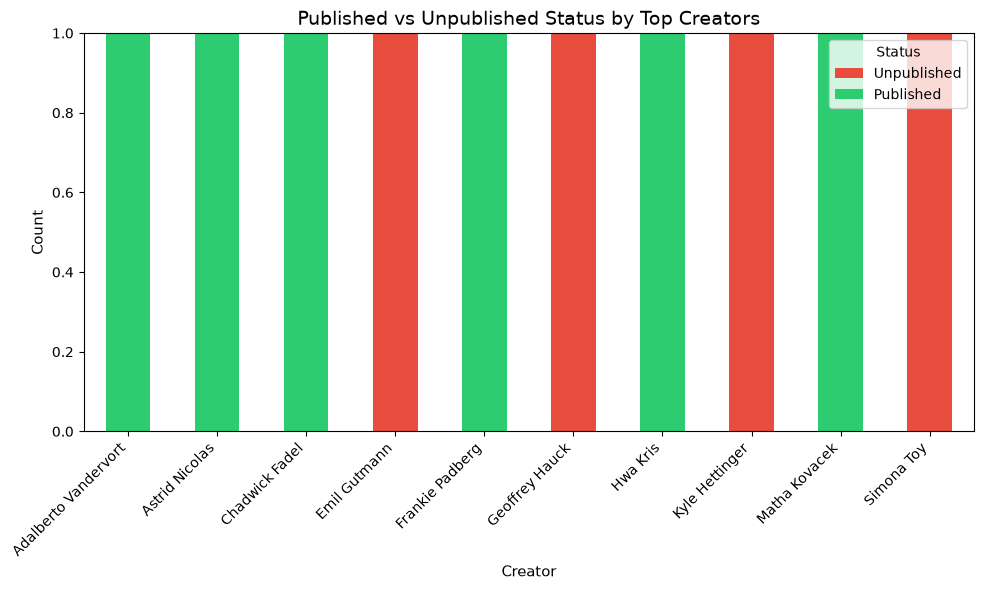

In [9]:
# Filter for top 10 creators to keep the chart clean
top_10_names = df['creator'].value_counts().head(10).index
filtered_df = df[df['creator'].isin(top_10_names)]

# Create a cross-tabulation table
cross_tab = pd.crosstab(filtered_df['creator'], filtered_df['published'])
print('Creator vs Published Status Crosstab:')
display(cross_tab)

# Visualization: Stacked Bar Chart
fig, ax = plt.subplots(figsize=(10, 6))
cross_tab.plot(
    kind='bar',
    stacked=True,
    color=['#e74c3c', '#2ecc71'],
    ax=ax,
)
ax.set_title('Published vs Unpublished Status by Top Creators')
ax.set_xlabel('Creator')
ax.set_ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.legend(['Unpublished', 'Published'], title='Status')
plt.tight_layout()
plt.show()

In [12]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure output directory exists
os.makedirs('eda_outputs', exist_ok=True)

# Set global clean aesthetics for charts
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 14})


# =====================================================================
# CHART 1: Top 5 Creators (Fixed & Clean Layout)
# =====================================================================
plt.figure(figsize=(10, 6))
top_creators = df['creator'].value_counts().head(5)

# Fixed: Added hue and legend=False to resolve the deprecation warning
sns.barplot(
    x=top_creators.index, 
    y=top_creators.values, 
    hue=top_creators.index, 
    palette="Blues_d", 
    legend=False
)

plt.title("Top 5 Content Creators", pad=20)
plt.xlabel("Creator Name")
plt.ylabel("Number of Tutorials")
plt.xticks(rotation=30, ha='right')

plt.tight_layout()
plt.savefig('eda_outputs/top_creators.png', bbox_inches='tight', dpi=300)
plt.close()


# =====================================================================
# CHART 2: Publication Status Breakdown (Pie Chart)
# =====================================================================
plt.figure(figsize=(6, 6))
publish_counts = df['published'].value_counts()
labels = ['Published (True)', 'Draft (False)'] if True in publish_counts.index else publish_counts.index

plt.pie(publish_counts, labels=labels, autopct='%1.1f%%', startangle=140, 
        colors=['#66b3ff','#ff9999'], explode=(0.05, 0))
plt.title("Tutorial Publication Status Distribution", pad=20)

plt.tight_layout()
plt.savefig('eda_outputs/publication_distribution.png', bbox_inches='tight', dpi=300)
plt.close()


# =====================================================================
# CHART 3: Title Length Distribution (Histogram + KDE Density Curve)
# =====================================================================
plt.figure(figsize=(9, 5))
df['title_length'] = df['title'].apply(lambda x: len(str(x)))

sns.histplot(df['title_length'], bins=15, kde=True, color='purple')
plt.title("Distribution of Tutorial Title Lengths (Characters)", pad=15)
plt.xlabel("Character Count")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig('eda_outputs/title_length_distribution.png', bbox_inches='tight', dpi=300)
plt.close()


# =====================================================================
# CHART 4: Publication Status Comparison across Top Creators (Grouped Chart)
# =====================================================================
plt.figure(figsize=(11, 6))
# Filter data for only top 5 creators to prevent overcrowding
top_5_names = df['creator'].value_counts().head(5).index
df_top_creators = df[df['creator'].isin(top_5_names)]

sns.countplot(data=df_top_creators, x='creator', hue='published', palette="Set2")
plt.title("Publication Status Breakdown per Top Creator", pad=20)
plt.xlabel("Creator Name")
plt.ylabel("Count")
plt.xticks(rotation=30, ha='right')
plt.legend(title='Published', labels=['False', 'True'])

plt.tight_layout()
plt.savefig('eda_outputs/creator_vs_published.png', bbox_inches='tight', dpi=300)
plt.close()

print("🎉 Success! All EDA charts generated cleanly inside the 'eda_outputs/' folder.")


🎉 Success! All EDA charts generated cleanly inside the 'eda_outputs/' folder.
